## Unemployment Dataset Exploration


#### Socio-economic Dataset Exploration & Harmonization



**Project:** AI-Powered Climate & ESG Risk Intelligence Platform for Multi-Sector Decision Support in Germany

**Notebook:** 07_socioeconomic_dataset_exploration_inkar_unemployment.ipynb

**Dataset:** Dataset: Arbeitslosenquote (Unemployment Rate) (INKAR)

**Source:** INKAR (Indikatoren und Karten zur Raum- und Stadtentwicklung), Federal Institute for Research on Building, Urban Affairs and Spatial Development (BBSR), Germany.

**Description** This notebook uses the INKAR (Indikatoren und Karten zur Raum- und Stadtentwicklung) dataset "Arbeitslosenquote", which provides annual unemployment rate statistics for approximately 400 German districts (Kreise) covering the period 1998–2023.

The unemployment rate is a widely used indicator of labour market conditions and serves as an important proxy for regional socio-economic vulnerability, resilience, and adaptive capacity in the context of climate-related hazards.

**Purpose** Selected as a socio-economic vulnerability indicator for the AI-Powered Climate & ESG Risk Intelligence Platform because labour market conditions influence household resilience, economic stability, and the capacity of communities to prepare for, respond to, and recover from climate-related shocks. Combined with climate hazard indicators, unemployment supports the assessment of regional climate risk and evidence-based decision making.

**Indicator type:** Socio-economic indicator (Social Vulnerability)

**Spatial focus:** Germany (Districts / Kreise / NUTS-3)

**Dataset coverage:** 1998–2023

**Project temporal focus:** 1990–2025

**Objective** To explore, evaluate, harmonize and preprocess the INKAR unemployment dataset for German districts (Kreise) in preparation for integration into the AI-Powered Climate & ESG Risk Intelligence Platform.

This notebook documents dataset characteristics, quality assessment, preprocessing decisions, temporal harmonization, and preparation for integration into the master Climate & ESG Risk Intelligence database.

### Import Libraries

In [26]:
# ------------------------------------------------------------
# Climate & ESG Risk Intelligence Germany
# ------------------------------------------------------------
# Dataset Exploration
# Dataset: Unemployment Rate (INKAR)
# Indicator: Unemployment Rate
# Category: Socio-economic Indicator (Social Vulnerability)
# Author: Purity Mbaabu
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

### Locate Dataset

In [4]:
# ============================================================
# Locate Unemployment dataset
# ============================================================

PROJECT_ROOT = Path.cwd().parent

unemployment_file = (
    PROJECT_ROOT
    / "data"
    / "incoming"
    / "socioeconomic"
    / "Unemployment_INKAR-1998-2023-Regions400.xlsx"
)

print(unemployment_file)
print(unemployment_file.exists())

d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\data\incoming\socioeconomic\Unemployment_INKAR-1998-2023-Regions400.xlsx
True


### Load Dataset

In [5]:
# =========================================================
# Load Unemployment data
# =========================================================

unemployment = pd.read_excel(
    unemployment_file,
    sheet_name="Daten"
)

print(unemployment.shape)
unemployment.head()

(401, 29)


,Kennziffer,Raumeinheit,Aggregat,Arbeitslosenquote,Arbeitslosenquote.1,Arbeitslosenquote.2,Arbeitslosenquote.3,Arbeitslosenquote.4,Arbeitslosenquote.5,Arbeitslosenquote.6,...,Arbeitslosenquote.16,Arbeitslosenquote.17,Arbeitslosenquote.18,Arbeitslosenquote.19,Arbeitslosenquote.20,Arbeitslosenquote.21,Arbeitslosenquote.22,Arbeitslosenquote.23,Arbeitslosenquote.24,Arbeitslosenquote.25
0,NaN,NaN,NaN,1998.00,1999.00,2000.00,2001.00,2002.00,2003.00,2004.00,...,2014.00,2015.00,2016.00,2017.00,2018.00,2019.00,2020.00,2021.00,2022.00,2023.00
1,1001.0,"Flensburg, Stadt",Kreise,14.60,13.00,11.84,12.12,12.09,13.68,14.02,...,10.55,9.96,9.03,8.95,8.31,7.96,9.06,8.45,7.69,7.88
2,1002.0,"Kiel, Landeshauptstadt",Kreise,13.90,12.88,11.31,11.12,11.69,13.42,13.61,...,10.08,9.87,9.66,9.08,8.18,7.59,8.48,8.00,7.44,7.56
3,1003.0,"Lübeck, Hansestadt",Kreise,13.41,13.42,12.60,12.26,12.62,13.68,13.98,...,10.13,9.90,9.07,8.60,7.78,7.28,8.14,8.08,7.59,7.88
4,1004.0,"Neumünster, Stadt",Kreise,13.45,13.39,12.20,11.79,12.07,13.40,13.52,...,10.92,10.23,9.56,9.21,8.34,7.90,8.92,8.71,7.77,8.34


##### Inspect workbook

In [6]:
# =========================================================
# Inspect workbook
# =========================================================

xls = pd.ExcelFile(unemployment_file)

print("Sheets:")
print(xls.sheet_names)

Sheets:
['Daten', 'Metadaten', 'Quellangabe']


##### Preview the first few rows without headers

In [7]:
# =========================================================
# Preview raw workbook structure
# =========================================================

preview = pd.read_excel(
    unemployment_file,
    sheet_name="Daten",
    header=None,
    nrows=8
)

preview

,0,1,2,3,4,5,6,7,8,9,...,19,20,21,22,23,24,25,26,27,28
0,Kennziffer,Raumeinheit,Aggregat,Arbeitslosenquote,Arbeitslosenquote,Arbeitslosenquote,Arbeitslosenquote,Arbeitslosenquote,Arbeitslosenquote,Arbeitslosenquote,...,Arbeitslosenquote,Arbeitslosenquote,Arbeitslosenquote,Arbeitslosenquote,Arbeitslosenquote,Arbeitslosenquote,Arbeitslosenquote,Arbeitslosenquote,Arbeitslosenquote,Arbeitslosenquote
1,NaN,NaN,NaN,1998,1999,2000,2001,2002,2003,2004,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
2,01001,"Flensburg, Stadt",Kreise,14.6,13,11.84,12.12,12.09,13.68,14.02,...,10.55,9.96,9.03,8.95,8.31,7.96,9.06,8.45,7.69,7.88
3,01002,"Kiel, Landeshauptstadt",Kreise,13.9,12.88,11.31,11.12,11.69,13.42,13.61,...,10.08,9.87,9.66,9.08,8.18,7.59,8.48,8,7.44,7.56
4,01003,"Lübeck, Hansestadt",Kreise,13.41,13.42,12.6,12.26,12.62,13.68,13.98,...,10.13,9.9,9.07,8.6,7.78,7.28,8.14,8.08,7.59,7.88
5,01004,"Neumünster, Stadt",Kreise,13.45,13.39,12.2,11.79,12.07,13.4,13.52,...,10.92,10.23,9.56,9.21,8.34,7.9,8.92,8.71,7.77,8.34
6,01051,Dithmarschen,Kreise,10.7,10.02,8.99,9.25,9.2,10.5,11.14,...,7.38,7.34,7.19,6.83,6.27,5.49,6.09,5.9,5.5,5.83
7,01053,Herzogtum Lauenburg,Kreise,8.32,8,7.54,7.7,7.74,8.6,8.86,...,6.05,5.83,5.66,5.47,4.97,4.68,5.47,5.27,5.03,5.19


##### Inspect dataframe structure

In [8]:
# =========================================================
# Inspect dataframe structure
# =========================================================

print(f"Rows: {unemployment.shape[0]}")
print(f"Columns: {unemployment.shape[1]}")

print("\nColumn names:")
print(unemployment.columns.tolist())

Rows: 401
Columns: 29

Column names:
['Kennziffer', 'Raumeinheit', 'Aggregat', 'Arbeitslosenquote', 'Arbeitslosenquote.1', 'Arbeitslosenquote.2', 'Arbeitslosenquote.3', 'Arbeitslosenquote.4', 'Arbeitslosenquote.5', 'Arbeitslosenquote.6', 'Arbeitslosenquote.7', 'Arbeitslosenquote.8', 'Arbeitslosenquote.9', 'Arbeitslosenquote.10', 'Arbeitslosenquote.11', 'Arbeitslosenquote.12', 'Arbeitslosenquote.13', 'Arbeitslosenquote.14', 'Arbeitslosenquote.15', 'Arbeitslosenquote.16', 'Arbeitslosenquote.17', 'Arbeitslosenquote.18', 'Arbeitslosenquote.19', 'Arbeitslosenquote.20', 'Arbeitslosenquote.21', 'Arbeitslosenquote.22', 'Arbeitslosenquote.23', 'Arbeitslosenquote.24', 'Arbeitslosenquote.25']


##### Clean the column names

In [9]:
# =========================================================
# Harmonize column names
# =========================================================

new_columns = [
    "district_code",
    "district_name",
    "aggregation_level"
]

years = unemployment.iloc[0, 3:].astype(int).astype(str).tolist()

new_columns.extend(years)

unemployment.columns = new_columns

unemployment.head()

,district_code,district_name,aggregation_level,1998,1999,2000,2001,2002,2003,2004,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,NaN,NaN,NaN,1998.00,1999.00,2000.00,2001.00,2002.00,2003.00,2004.00,...,2014.00,2015.00,2016.00,2017.00,2018.00,2019.00,2020.00,2021.00,2022.00,2023.00
1,1001.0,"Flensburg, Stadt",Kreise,14.60,13.00,11.84,12.12,12.09,13.68,14.02,...,10.55,9.96,9.03,8.95,8.31,7.96,9.06,8.45,7.69,7.88
2,1002.0,"Kiel, Landeshauptstadt",Kreise,13.90,12.88,11.31,11.12,11.69,13.42,13.61,...,10.08,9.87,9.66,9.08,8.18,7.59,8.48,8.00,7.44,7.56
3,1003.0,"Lübeck, Hansestadt",Kreise,13.41,13.42,12.60,12.26,12.62,13.68,13.98,...,10.13,9.90,9.07,8.60,7.78,7.28,8.14,8.08,7.59,7.88
4,1004.0,"Neumünster, Stadt",Kreise,13.45,13.39,12.20,11.79,12.07,13.40,13.52,...,10.92,10.23,9.56,9.21,8.34,7.90,8.92,8.71,7.77,8.34


##### Remove the year row

In [10]:
# =========================================================
# Remove year row
# =========================================================

unemployment = unemployment.iloc[1:].reset_index(drop=True)

print(unemployment.shape)
unemployment.head()

(400, 29)


,district_code,district_name,aggregation_level,1998,1999,2000,2001,2002,2003,2004,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,1001.0,"Flensburg, Stadt",Kreise,14.60,13.00,11.84,12.12,12.09,13.68,14.02,...,10.55,9.96,9.03,8.95,8.31,7.96,9.06,8.45,7.69,7.88
1,1002.0,"Kiel, Landeshauptstadt",Kreise,13.90,12.88,11.31,11.12,11.69,13.42,13.61,...,10.08,9.87,9.66,9.08,8.18,7.59,8.48,8.00,7.44,7.56
2,1003.0,"Lübeck, Hansestadt",Kreise,13.41,13.42,12.60,12.26,12.62,13.68,13.98,...,10.13,9.90,9.07,8.60,7.78,7.28,8.14,8.08,7.59,7.88
3,1004.0,"Neumünster, Stadt",Kreise,13.45,13.39,12.20,11.79,12.07,13.40,13.52,...,10.92,10.23,9.56,9.21,8.34,7.90,8.92,8.71,7.77,8.34
4,1051.0,Dithmarschen,Kreise,10.70,10.02,8.99,9.25,9.20,10.50,11.14,...,7.38,7.34,7.19,6.83,6.27,5.49,6.09,5.90,5.50,5.83


##### Verify district count

In [11]:
# =========================================================
# Verify district coverage
# =========================================================

print("Aggregation levels:")
print(unemployment["aggregation_level"].value_counts())

print()

print("Number of districts:")
print(len(unemployment))

Aggregation levels:
aggregation_level
Kreise    400
Name: count, dtype: int64

Number of districts:
400


##### Check for duplicate district codes

In [12]:
# ==========================================================
# Check duplicate district codes
# ==========================================================

duplicates = unemployment["district_code"].duplicated().sum()

print("Duplicate district codes:", duplicates)

Duplicate district codes: 0


##### Check missing values

In [13]:
# ==========================================================
# Missing values
# ==========================================================

missing = unemployment.isna().sum()

print(missing[missing > 0])

Series([], dtype: int64)


##### Summary Statistics

In [14]:
# =========================================================
# Summary statistics
# =========================================================

unemployment.iloc[:, 3:].describe().T

,count,mean,std,min,25%,50%,75%,max
1998,400.0,10.703000,4.524673,4.04,7.3000,9.275,13.1800,23.63
1999,400.0,10.095300,4.452674,3.41,6.8400,8.770,12.6275,23.00
2000,400.0,9.247525,4.691181,2.63,5.8600,7.690,11.6425,22.72
2001,400.0,9.002550,4.826001,2.63,5.5825,7.395,11.2225,23.34
2002,400.0,9.436150,4.716715,3.32,6.0100,7.830,11.3750,23.05
2003,400.0,10.194675,4.812801,4.15,6.8275,8.535,12.2000,24.93
2004,400.0,10.275300,4.834723,4.02,6.8850,8.735,12.2575,25.43
2005,400.0,11.336325,4.769048,4.30,7.7250,10.120,14.1025,24.84
2006,400.0,10.355150,4.486911,3.42,6.8800,9.215,13.1525,23.66
2007,400.0,8.633325,4.167637,2.18,5.2500,7.385,11.0975,21.91


##### Visualization

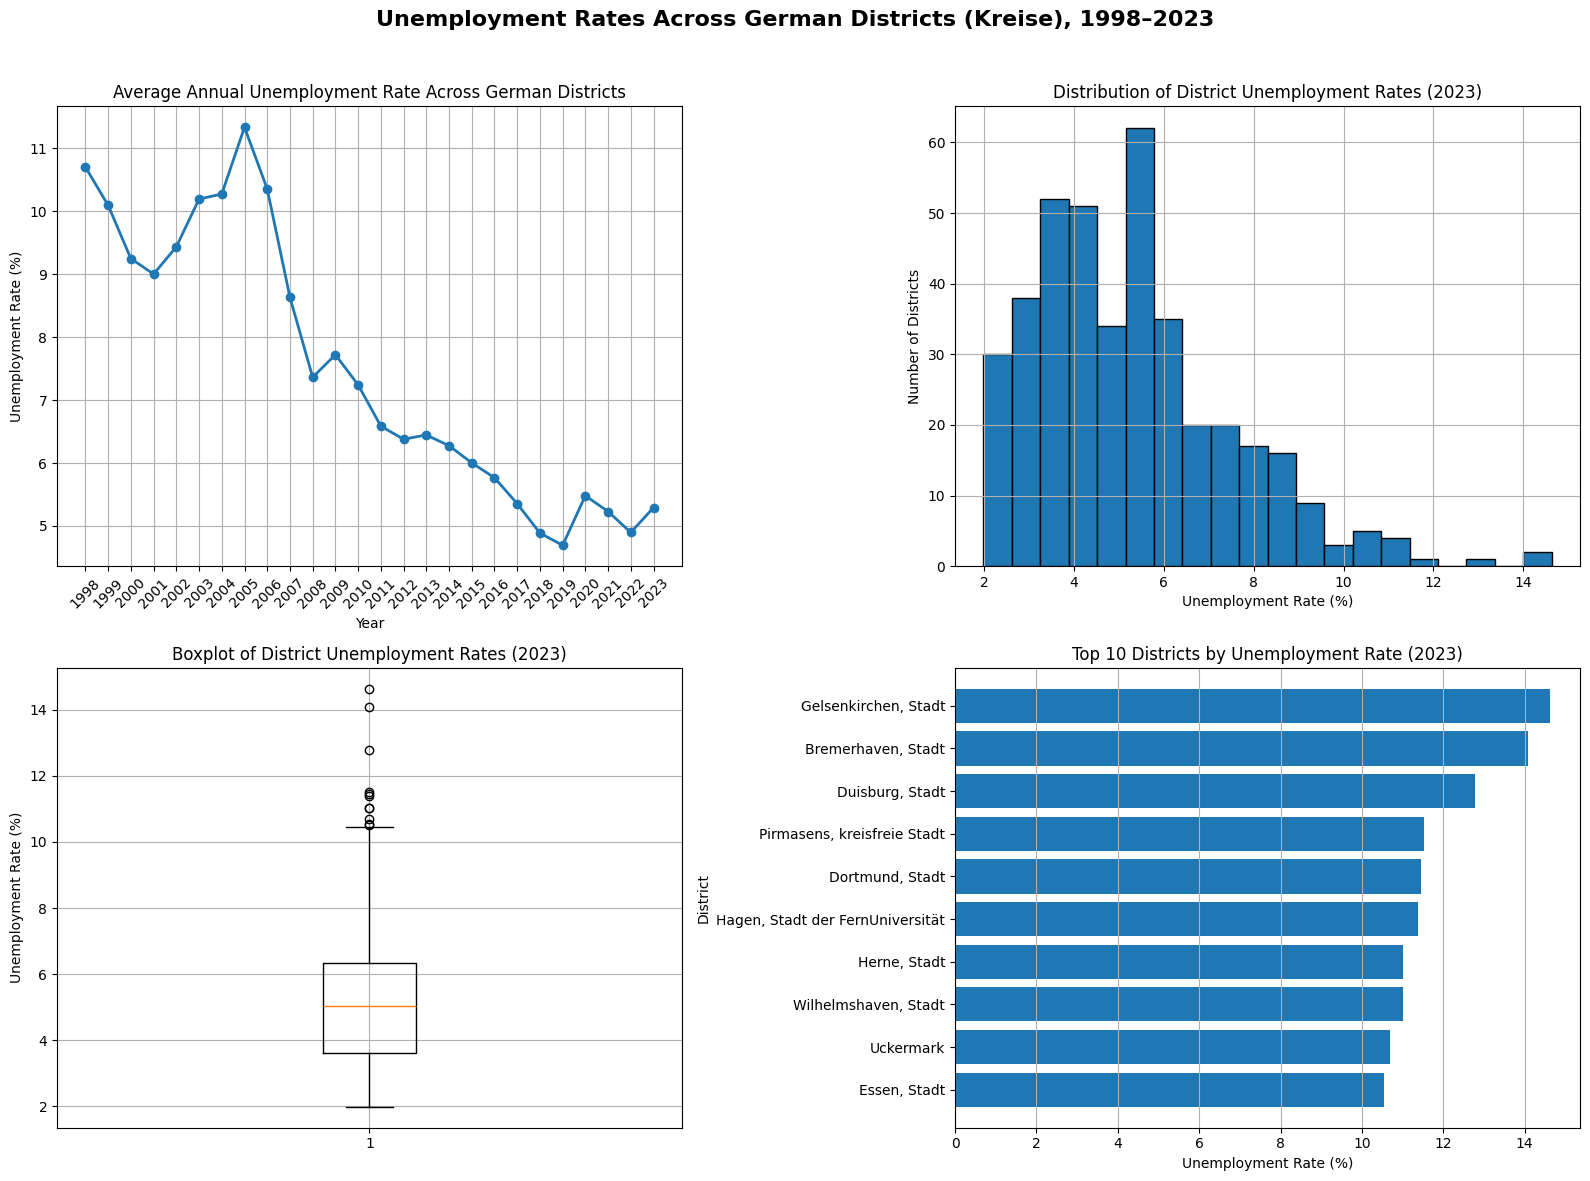

In [ ]:
# ============================================================
# Visualizations
# ============================================================


# Select annual unemployment columns
years = unemployment.columns[3:]
latest_year = years[-1]

# Calculate average annual unemployment
mean_unemployment = unemployment[years].mean()

# Top 10 districts in latest year
top10_latest = unemployment.sort_values(
    by=latest_year,
    ascending=False
).head(10)

# Create 2 × 2 figure
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

fig.suptitle(
    "Unemployment Rates Across German Districts (Kreise), 1998–2023",
    fontsize=16,
    fontweight="bold"
)

# 1. Average annual trend
axes[0, 0].plot(
    years,
    mean_unemployment.values,
    marker="o",
    linewidth=2
)

axes[0, 0].set_title("Average Annual Unemployment Rate Across German Districts")
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Unemployment Rate (%)")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].grid(True)

# 2. Distribution in latest year
axes[0, 1].hist(
    unemployment[latest_year],
    bins=20,
    edgecolor="black"
)

axes[0, 1].set_title(f"Distribution of District Unemployment Rates ({latest_year})")
axes[0, 1].set_xlabel("Unemployment Rate (%)")
axes[0, 1].set_ylabel("Number of Districts")
axes[0, 1].grid(True)

# 3. Boxplot in latest year
axes[1, 0].boxplot(
    unemployment[latest_year],
    vert=True
)

axes[1, 0].set_title(f"Boxplot of District Unemployment Rates ({latest_year})")
axes[1, 0].set_ylabel("Unemployment Rate (%)")
axes[1, 0].grid(True)

# 4. Top 10 districts in latest year
axes[1, 1].barh(
    top10_latest["district_name"],
    top10_latest[latest_year]
)

axes[1, 1].set_title(f"Top 10 Districts by Unemployment Rate ({latest_year})")
axes[1, 1].set_xlabel("Unemployment Rate (%)")
axes[1, 1].set_ylabel("District")
axes[1, 1].invert_yaxis()
axes[1, 1].grid(True, axis="x")

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()




##### Convert district codes to official 5-digit strings

Convert district identifiers to the official five-digit German AGS (Amtlicher Gemeindeschlüssel) format to ensure compatibility with other climate, administrative boundary, and socio-economic datasets.

In [19]:
# ==========================================================
# Format district codes
# ==========================================================

unemployment["district_code"] = (
    unemployment["district_code"]
    .astype(int)
    .astype(str)
    .str.zfill(5)
)

unemployment.head()

,district_code,district_name,aggregation_level,1998,1999,2000,2001,2002,2003,2004,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,01001,"Flensburg, Stadt",Kreise,14.60,13.00,11.84,12.12,12.09,13.68,14.02,...,10.55,9.96,9.03,8.95,8.31,7.96,9.06,8.45,7.69,7.88
1,01002,"Kiel, Landeshauptstadt",Kreise,13.90,12.88,11.31,11.12,11.69,13.42,13.61,...,10.08,9.87,9.66,9.08,8.18,7.59,8.48,8.00,7.44,7.56
2,01003,"Lübeck, Hansestadt",Kreise,13.41,13.42,12.60,12.26,12.62,13.68,13.98,...,10.13,9.90,9.07,8.60,7.78,7.28,8.14,8.08,7.59,7.88
3,01004,"Neumünster, Stadt",Kreise,13.45,13.39,12.20,11.79,12.07,13.40,13.52,...,10.92,10.23,9.56,9.21,8.34,7.90,8.92,8.71,7.77,8.34
4,01051,Dithmarschen,Kreise,10.70,10.02,8.99,9.25,9.20,10.50,11.14,...,7.38,7.34,7.19,6.83,6.27,5.49,6.09,5.90,5.50,5.83


##### Verify formatted district codes

In [20]:
# ==========================================================
# Verify district codes
# ==========================================================

print(unemployment["district_code"].head())

print()
print("Unique district codes:", unemployment["district_code"].nunique())

0    01001
1    01002
2    01003
3    01004
4    01051
Name: district_code, dtype: object

Unique district codes: 400


##### Convert from wide to long format


Transform annual unemployment columns into a single year column and a single unemployment_rate column.

This tidy format is required for merging with climate indicators and for machine learning workflows.

In [21]:
# ==========================================================
# Convert wide table to long format
# ==========================================================

unemployment_long = unemployment.melt(
    id_vars=[
        "district_code",
        "district_name",
        "aggregation_level"
    ],
    var_name="year",
    value_name="unemployment_rate"
)

unemployment_long.head()

,district_code,district_name,aggregation_level,year,unemployment_rate
0,01001,"Flensburg, Stadt",Kreise,1998,14.60
1,01002,"Kiel, Landeshauptstadt",Kreise,1998,13.90
2,01003,"Lübeck, Hansestadt",Kreise,1998,13.41
3,01004,"Neumünster, Stadt",Kreise,1998,13.45
4,01051,Dithmarschen,Kreise,1998,10.70


##### Convert data types

In [22]:
# ============================================================
# Convert data types
# ============================================================

unemployment_long["year"] = unemployment_long["year"].astype(int)

unemployment_long["unemployment_rate"] = (
    pd.to_numeric(
        unemployment_long["unemployment_rate"],
        errors="coerce"
    )
)

##### Verify the transformed dataset

In [23]:
# ============================================================
# Verify transformed dataset
# ============================================================

print(unemployment_long.shape)

unemployment_long.head()

(10400, 5)


,district_code,district_name,aggregation_level,year,unemployment_rate
0,01001,"Flensburg, Stadt",Kreise,1998,14.60
1,01002,"Kiel, Landeshauptstadt",Kreise,1998,13.90
2,01003,"Lübeck, Hansestadt",Kreise,1998,13.41
3,01004,"Neumünster, Stadt",Kreise,1998,13.45
4,01051,Dithmarschen,Kreise,1998,10.70


##### Quality checks

In [24]:
# ============================================================
# Quality checks after transformation
# ============================================================

print("Missing values")
print(unemployment_long.isna().sum())

print()

print("Duplicate rows")
print(unemployment_long.duplicated().sum())

print()

print("Unique districts")
print(unemployment_long["district_code"].nunique())

print()

print("Years")
print(
    unemployment_long["year"].min(),
    "-",
    unemployment_long["year"].max()
)

Missing values
district_code        0
district_name        0
aggregation_level    0
year                 0
unemployment_rate    0
dtype: int64

Duplicate rows
0

Unique districts
400

Years
1998 - 2023


##### Save the cleaned dataset

In [25]:
# ============================================================
# Save cleaned unemployment dataset
# ============================================================

output_file = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "socioeconomic"
    / "unemployment_inkar_1998_2023.csv"
)

unemployment_long.to_csv(
    output_file,
    index=False
)

print(output_file)

d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\data\raw\socioeconomic\unemployment_inkar_1998_2023.csv


### Temporal Harmonization by Boundary-Year Imputation

The Climate & ESG Risk Intelligence project adopts a common temporal reference period of 1990–2025 to ensure temporal consistency across all climate hazard and socioeconomic indicators included in the project.

The harmonized INKAR unemployment dataset provides annual observations for 1998–2023, resulting in an eight-year gap at the beginning of the project period (1990–1997) and a two-year gap at the end (2024–2025).

To create a temporally consistent dataset for integration into the master Climate & ESG Risk Intelligence database, boundary-year imputation is applied using a conservative carry-backward and carry-forward approach. This method preserves the observed characteristics of the original INKAR dataset while avoiding the introduction of artificial trends or unsupported assumptions.

Specifically:

- 1990–1997 are populated using the earliest available observations from 1998.
- 2024–2025 are populated using the latest available observations from 2023.

As shown in the temporal trend analysis above, the average unemployment rate across German districts exhibits a long-term decline between 1998 and 2023, interrupted only by short-term fluctuations associated with economic cycles. However, reliable estimation of unemployment rates outside the observed period would require additional historical evidence or forecasting assumptions. Rather than extrapolating the observed trend beyond the available data, this study adopts a conservative boundary-value imputation strategy in which the earliest available observations (1998) are used to populate 1990–1997 and the latest available observations (2023) are used to populate 2024–2025. This approach preserves the integrity of the original INKAR dataset, avoids introducing unsupported temporal patterns or forecasting assumptions, and maintains methodological consistency across all socioeconomic indicators included in the Climate & ESG Risk Intelligence framework.

This harmonization strategy is applied consistently across all socioeconomic indicators to ensure methodological consistency, reproducibility, and compatibility with the project's unified temporal framework.

The temporally harmonized dataset generated in the following section forms the socioeconomic unemployment component of the integrated Climate & ESG Risk Intelligence master dataset.

In [ ]:
# =============================================================================
# Temporal Harmonization: Extend Unemployment Dataset to 1990–2025
# =============================================================================

print("=" * 80)
print("TEMPORAL HARMONIZATION: UNEMPLOYMENT DATASET")
print("=" * 80)

# Check original temporal coverage
original_start_year = unemployment_long["year"].min()
original_end_year = unemployment_long["year"].max()

print(f"Original temporal coverage : {original_start_year}–{original_end_year}")
print(f"Original districts         : {unemployment_long['district_code'].nunique()}")
print(f"Original observations      : {len(unemployment_long):,}")

# -----------------------------------------------------------------------------
# 1. Backward Boundary-Year Imputation (1990–1997 using 1998 observations)
# -----------------------------------------------------------------------------

base_1998 = unemployment_long[
    unemployment_long["year"] == 1998
].copy()

backfill = []

for yr in range(1990, 1998):
    temp = base_1998.copy()
    temp["year"] = yr
    temp["imputation_flag"] = "backfilled_from_1998"
    backfill.append(temp)

backfill = pd.concat(backfill, ignore_index=True)

# -----------------------------------------------------------------------------
# 2. Forward Boundary-Year Imputation (2024–2025 using 2023 observations)
# -----------------------------------------------------------------------------

base_2023 = unemployment_long[
    unemployment_long["year"] == 2023
].copy()

forwardfill = []

for yr in [2024, 2025]:
    temp = base_2023.copy()
    temp["year"] = yr
    temp["imputation_flag"] = "forwardfilled_from_2023"
    forwardfill.append(temp)

forwardfill = pd.concat(forwardfill, ignore_index=True)

# -----------------------------------------------------------------------------
# 3. Add flag to observed INKAR data
# -----------------------------------------------------------------------------

unemployment_observed = unemployment_long.copy()
unemployment_observed["imputation_flag"] = "observed_inkar"

# -----------------------------------------------------------------------------
# 4. Combine observed and imputed records
# -----------------------------------------------------------------------------

unemployment_harmonized = pd.concat(
    [backfill, unemployment_observed, forwardfill],
    ignore_index=True
)

unemployment_harmonized = unemployment_harmonized.sort_values(
    ["district_code", "year"]
).reset_index(drop=True)

# -----------------------------------------------------------------------------
# 5. Validate harmonized dataset
# -----------------------------------------------------------------------------

expected_years = list(range(1990, 2026))
expected_rows = 400 * len(expected_years)

print("\n" + "=" * 80)
print("VALIDATION AFTER TEMPORAL HARMONIZATION")
print("=" * 80)

print(f"Final temporal coverage : {unemployment_harmonized['year'].min()}–{unemployment_harmonized['year'].max()}")
print(f"Final districts         : {unemployment_harmonized['district_code'].nunique()}")
print(f"Final observations      : {len(unemployment_harmonized):,}")
print(f"Expected observations   : {expected_rows:,}")

print("\nRecords by imputation status:")
print(unemployment_harmonized["imputation_flag"].value_counts())

# Validation checks
assert unemployment_harmonized["year"].min() == 1990
assert unemployment_harmonized["year"].max() == 2025
assert unemployment_harmonized["district_code"].nunique() == 400
assert len(unemployment_harmonized) == expected_rows

duplicates = unemployment_harmonized.duplicated(
    subset=["district_code", "year"]
).sum()

print(f"\nDuplicate district-year records: {duplicates}")
assert duplicates == 0

print("\n✓ Temporal harmonization completed successfully.")

TEMPORAL HARMONIZATION: UNEMPLOYMENT DATASET
Original temporal coverage : 1998–2023
Original districts         : 400
Original observations      : 10,400

VALIDATION AFTER TEMPORAL HARMONIZATION
Final temporal coverage : 1990–2025
Final districts         : 400
Final observations      : 14,400
Expected observations   : 14,400

Records by imputation status:
imputation_flag
observed_inkar             10400
backfilled_from_1998        3200
forwardfilled_from_2023      800
Name: count, dtype: int64

Duplicate district-year records: 0

✓ Temporal harmonization completed successfully.


##### Save Temporally Harmonized Dataset

The temporally harmonized unemployment dataset (1990–2025) is exported to the processed data directory. This dataset represents the analysis-ready unemployment component prior to administrative harmonization and integration into the Climate & ESG Risk Intelligence master dataset.

In [28]:
# =============================================================================
# Export Temporally Harmonized Dataset
# =============================================================================

output_file = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "socioeconomic"
    / "unemployment_inkar_1990_2025.csv"
)

unemployment_harmonized.to_csv(
    output_file,
    index=False
)

print("=" * 80)
print("DATASET EXPORTED SUCCESSFULLY")
print("=" * 80)
print(output_file)

DATASET EXPORTED SUCCESSFULLY
d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\data\processed\socioeconomic\unemployment_inkar_1990_2025.csv
